In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from matplotlib import pyplot as plt

# Climatology Exploration

In [ ]:
pr_dekad = xr.open_dataset("../data/processed/pr_dekad_climatology_natraum_2001_2025.nc")
tas_dekad = xr.open_dataset("../data/processed/tas_dekad_climatology_natraum_2001_2025.nc")
tasmin_dekad = xr.open_dataset("../data/processed/tasmin_dekad_climatology_natraum_2001_2025.nc")
tasmax_dekad = xr.open_dataset("../data/processed/tasmax_dekad_climatology_natraum_2001_2025.nc")
smtop_dekad = xr.open_dataset("../data/processed/sw_dwd_0_10_dekad_climatology_natraum_2001_2025.nc")
smmid_dekad = xr.open_dataset("../data/processed/sw_dwd_90_100_dekad_climatology_natraum_2001_2025.nc")
smlow_dekad = xr.open_dataset("../data/processed/sw_dwd_190_200_dekad_climatology_natraum_2001_2025.nc")

In [2]:
dtr_clim = xr.open_dataset("../data/processed/dtr_dekad_climatology_natraum_2001_2025.nc")

In [4]:
pr_dekad.var

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 46kB
Dimensions:    (region_id: 79, month: 12, dekad: 3)
Coordinates:
  * region_id  (region_id) float64 632B 1.0 2.0 3.0 4.0 ... 76.0 77.0 78.0 79.0
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Data variables:
    mean       (region_id, month, dekad) float32 11kB ...
    std        (region_id, month, dekad) float32 11kB ...
    n_years    (region_id, month, dekad) int64 23kB ...
Attributes:
    description:  Calendar-dekad climatology for pr, calculated over 2001-2025.>

In [5]:
variables = {"pr": pr_dekad, "tas": tas_dekad, "tasmin": tasmin_dekad, "tasmax": tasmax_dekad, 
             "smtop": smtop_dekad, "smmid": smmid_dekad, "smlow": smlow_dekad}

#Cody by ChatGPT
for name, var in variables.items():
    print(
        f"{name:8s} "
        f"mean range: {float(var['mean'].min()):8.2f} - "
        f"{float(var['mean'].max()):8.2f} | "
        f"std range: {float(var['std'].min()):8.2f} - "
        f"{float(var['std'].max()):8.2f}"
        f"{float(var['n_years'].min()):8.2f} - "
        f"{float(var['n_years'].max()):8.2f}"
    )

pr       mean range:     6.70 -    37.08 | std range:     4.21 -    38.58   25.00 -    25.00
tas      mean range:    -0.14 -    20.44 | std range:     1.45 -     4.37   25.00 -    25.00
tasmin   mean range:    -9.37 -    11.76 | std range:     1.06 -     7.11   25.00 -    25.00
tasmax   mean range:     6.15 -    31.82 | std range:     2.11 -     4.90   25.00 -    25.00
smtop    mean range:    26.36 -   126.39 | std range:     4.19 -    40.69   25.00 -    25.00
smmid    mean range:    25.86 -   134.31 | std range:     5.18 -    42.89   25.00 -    25.00
smlow    mean range:    42.89 -   128.15 | std range:     3.91 -    28.69   25.00 -    25.00


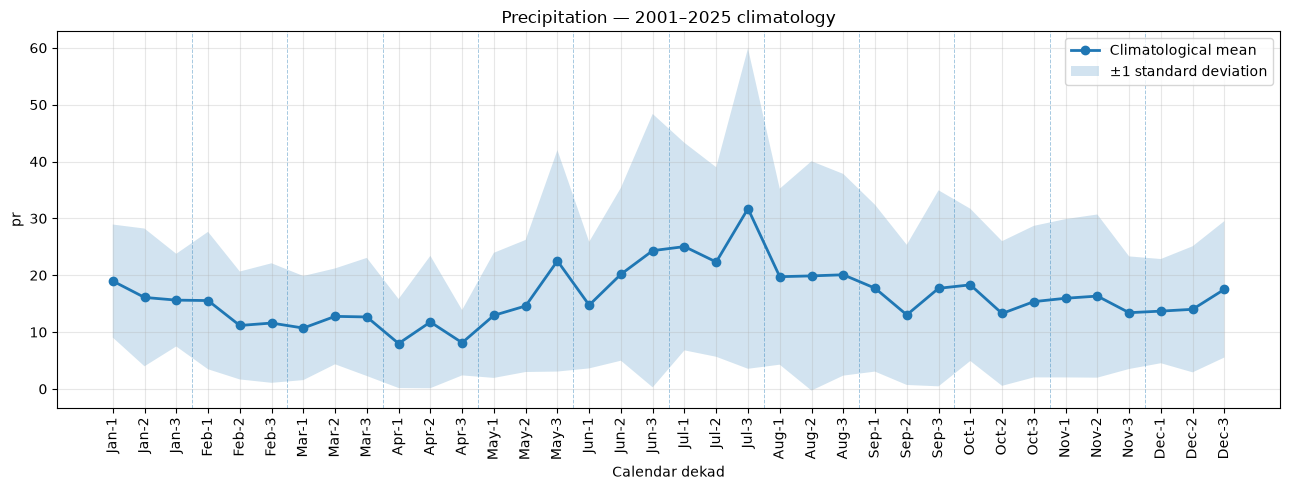

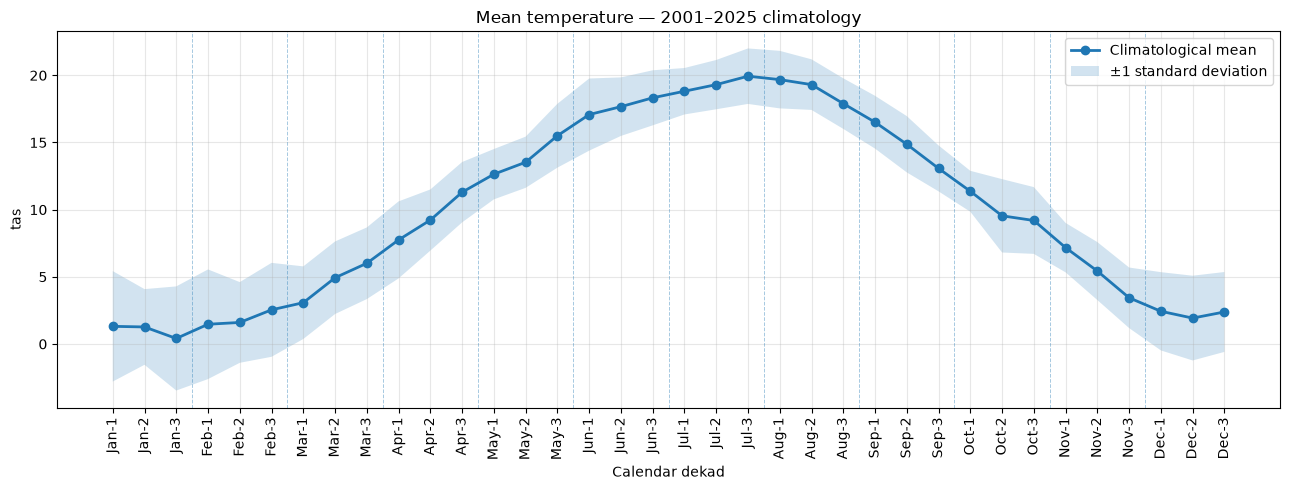

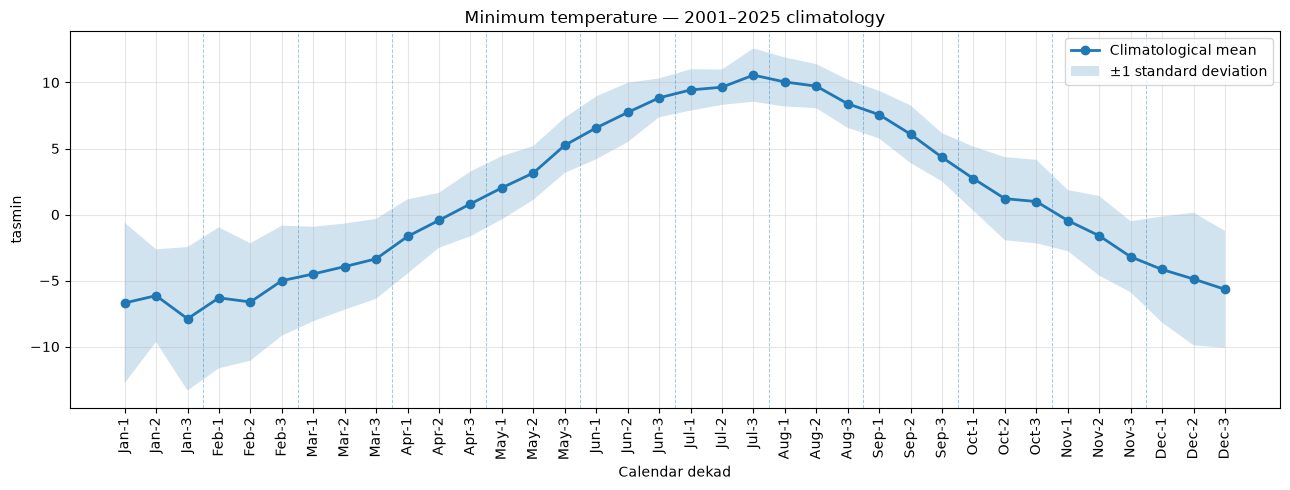

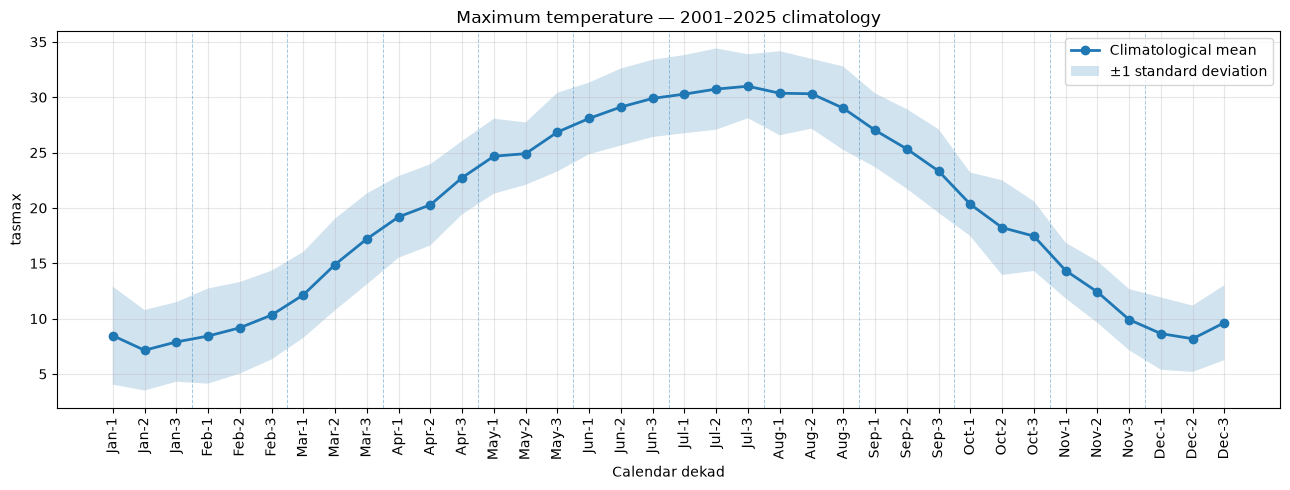

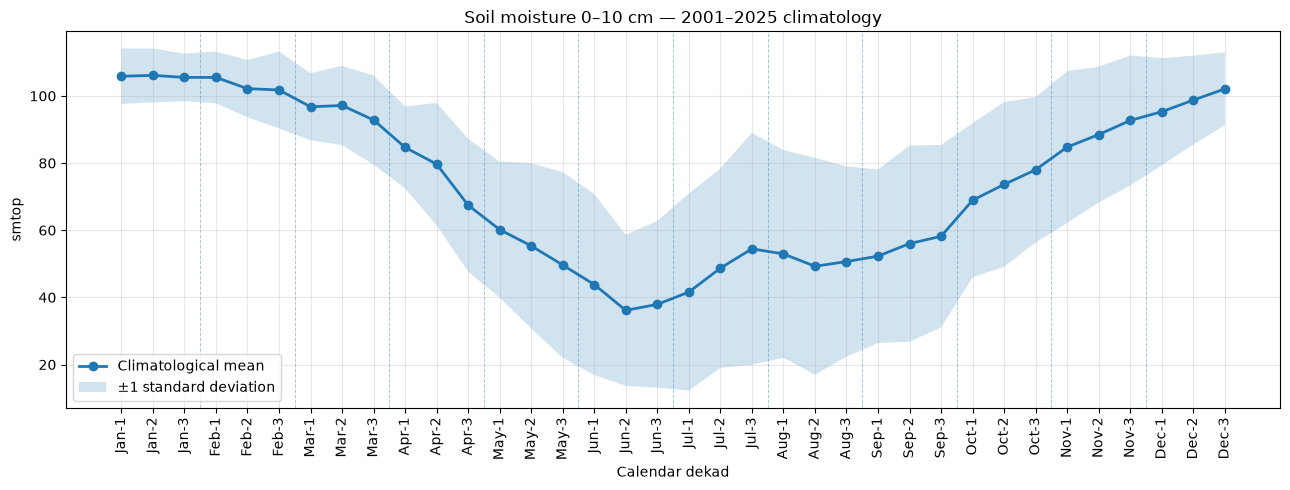

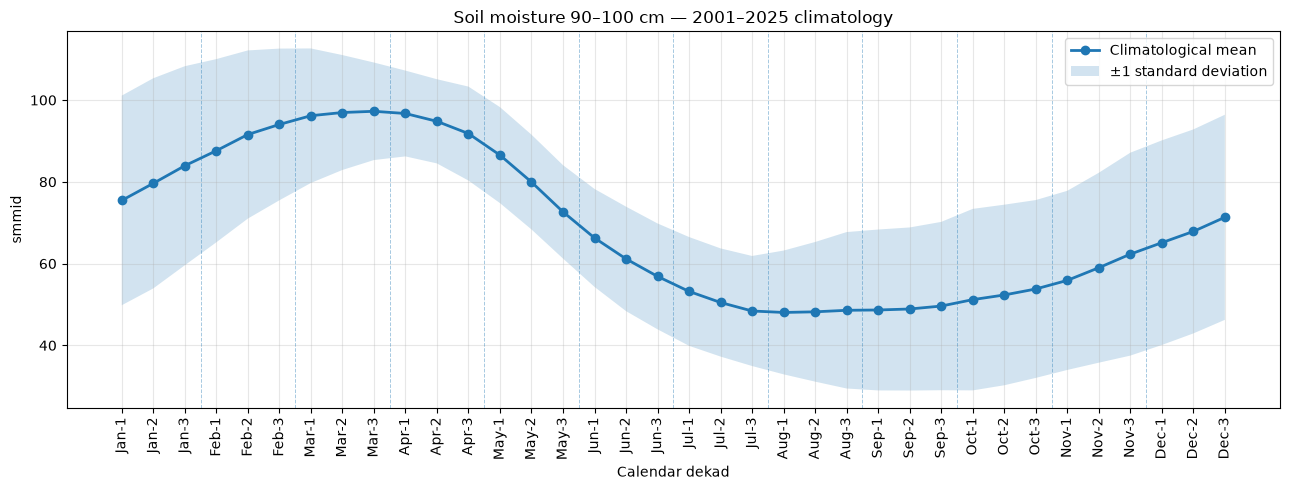

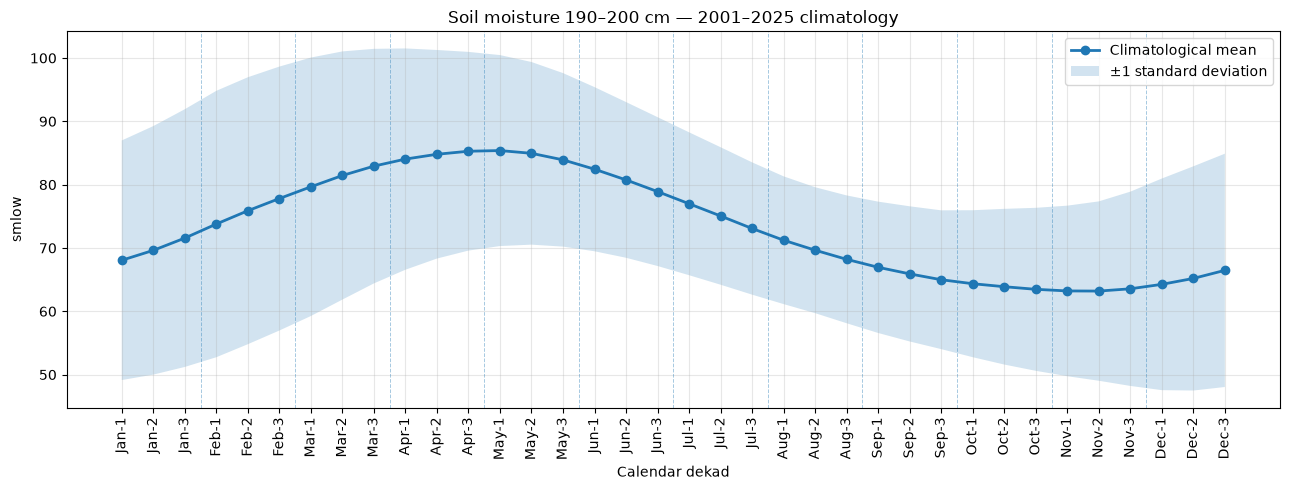

In [6]:
month_names = [    "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
dekad_labels = [
    f"{month_names[m-1]}-{d}"
    for m in range(1, 13)
    for d in range(1, 4)
]
# Code by ChatGPT
x = np.arange(36)

variable_labels = {
    "pr": "Precipitation",
    "tas": "Mean temperature",
    "tasmin": "Minimum temperature",
    "tasmax": "Maximum temperature",
    "smtop": "Soil moisture 0–10 cm",
    "smmid": "Soil moisture 90–100 cm",
    "smlow": "Soil moisture 190–200 cm",
}

variables = {
    "pr": pr_dekad,
    "tas": tas_dekad,
    "tasmin": tasmin_dekad,
    "tasmax": tasmax_dekad,
    "smtop": smtop_dekad,
    "smmid": smmid_dekad,
    "smlow": smlow_dekad,
}


for name, ds in variables.items():

    # Average the climatology across the 79 Naturräume
    mean = ds["mean"].mean(dim="region_id").values
    std = ds["std"].mean(dim="region_id").values

    # Flatten month/dekad dimensions into the 36 calendar dekads
    mean = mean.reshape(36)
    std = std.reshape(36)

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        x,
        mean,
        marker="o",
        linewidth=2,
        label="Climatological mean",
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.2,
        label="±1 standard deviation",
    )

    ax.set_title(
        f"{variable_labels[name]} — 2001–2025 climatology"
    )
    ax.set_xlabel("Calendar dekad")
    ax.set_ylabel(name)

    ax.set_xticks(x)
    ax.set_xticklabels(dekad_labels, rotation=90)

    # Show month boundaries
    for month in range(1, 12):
        ax.axvline(
            month * 3 - 0.5,
            linestyle="--",
            linewidth=0.7,
            alpha=0.4,
        )

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [3]:
# calculate overall climatology per NR across the dekads
NATRAUM = gpd.read_file("../data/brandenburg_shape/naturraum_scholz_ohne_Berlin_regionid.gpkg", layer="natraum_scholz_ohneBerlin_regionid")
natraum_3035 = NATRAUM.to_crs("EPSG:3035")

In [10]:
for name, ds in variables.items():

    regional_mean = ds["mean"].mean(dim=["month", "dekad"])

    min_region = regional_mean.idxmin(dim="region_id").item()
    max_region = regional_mean.idxmax(dim="region_id").item()

    min_value = regional_mean.sel(region_id=min_region).item()
    max_value = regional_mean.sel(region_id=max_region).item()

    min_name = natraum_3035.loc[
        natraum_3035["region_id"] == min_region,
        "NAME_UNTER"
    ].iloc[0]

    max_name = natraum_3035.loc[
        natraum_3035["region_id"] == max_region,
        "NAME_UNTER"
    ].iloc[0]

    print(f"\n{name}")
    print(f"  Lowest : region {min_region} — {min_name} ({min_value:.2f})")
    print(f"  Highest: region {max_region} — {max_name} ({max_value:.2f})")


pr
  Lowest : region 3.0 — Randowniederung (14.38)
  Highest: region 78.0 — Königsbrück-Ruhlander Heiden (18.24)

tas
  Lowest : region 2.0 — Woldegk-Feldberger Hügelland (9.30)
  Highest: region 43.0 — Teltowplatte (10.34)

tasmin
  Lowest : region 65.0 — Guben-Neißetal (0.32)
  Highest: region 48.0 — Beelitzer Heide (2.09)

tasmax
  Lowest : region 2.0 — Woldegk-Feldberger Hügelland (18.18)
  Highest: region 72.0 — Cottbusser Schwemmsandfächer (20.10)

smtop
  Lowest : region 71.0 — Lausitzer Grenzwall (62.89)
  Highest: region 17.0 — Mittelelbe Niederung (91.69)

smmid
  Lowest : region 59.0 — Zossen-Teupitzer Platten- und Hügelland (50.19)
  Highest: region 2.0 — Woldegk-Feldberger Hügelland (95.25)

smlow
  Lowest : region 20.0 — Zehdenick-Spandauer Havelniederung (56.35)
  Highest: region 2.0 — Woldegk-Feldberger Hügelland (108.03)


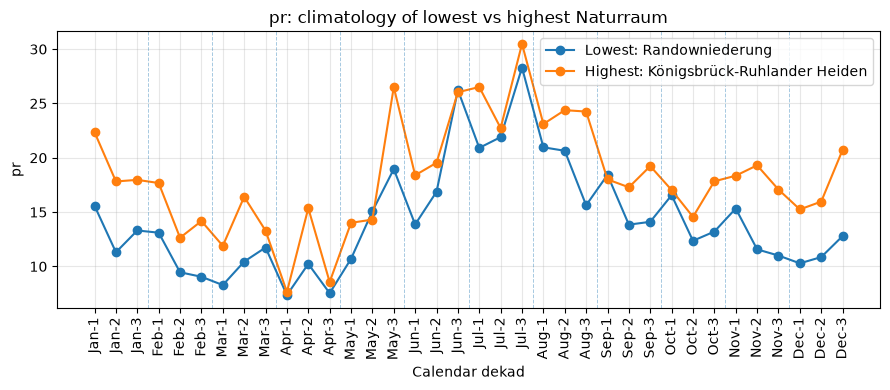

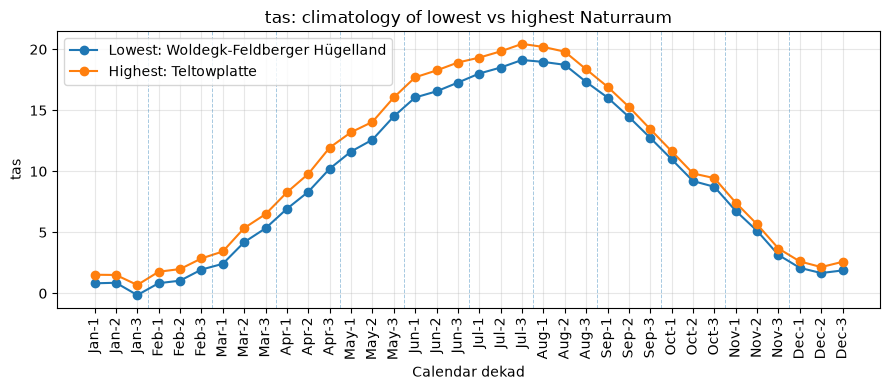

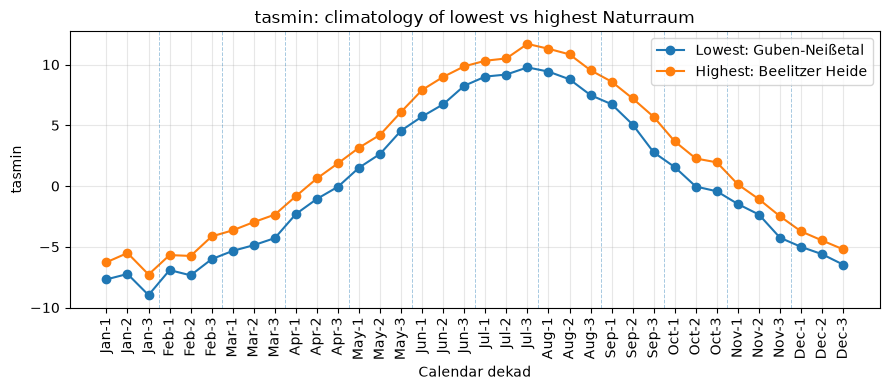

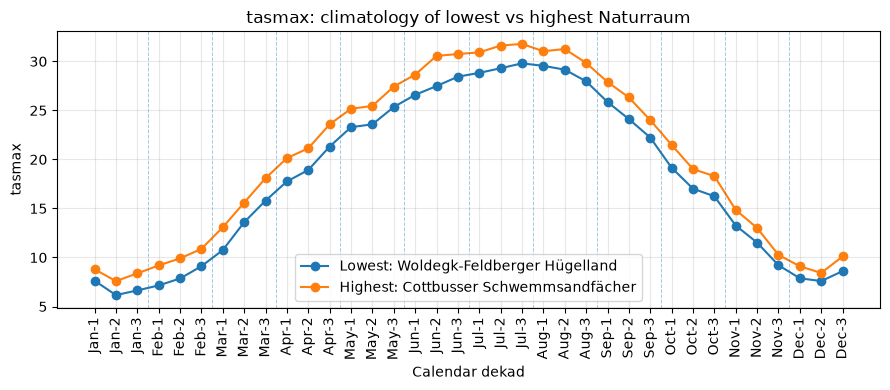

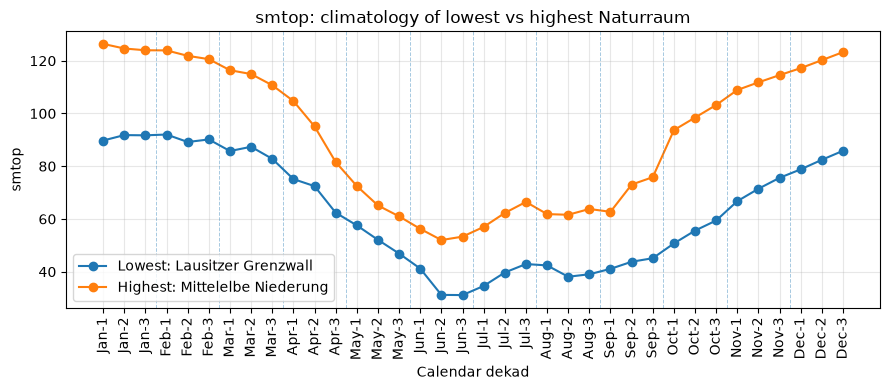

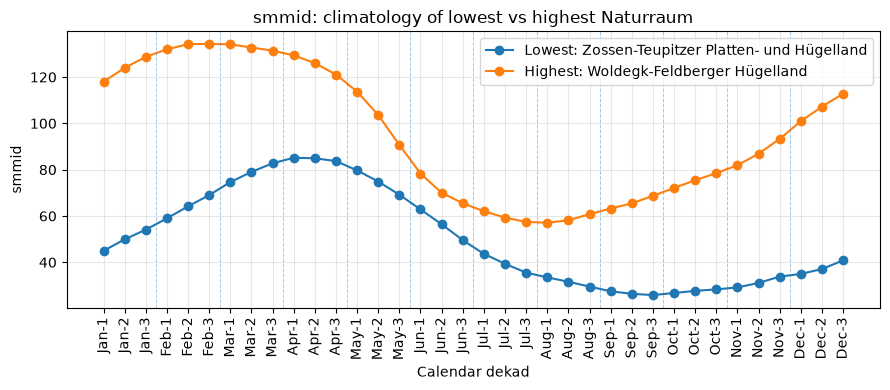

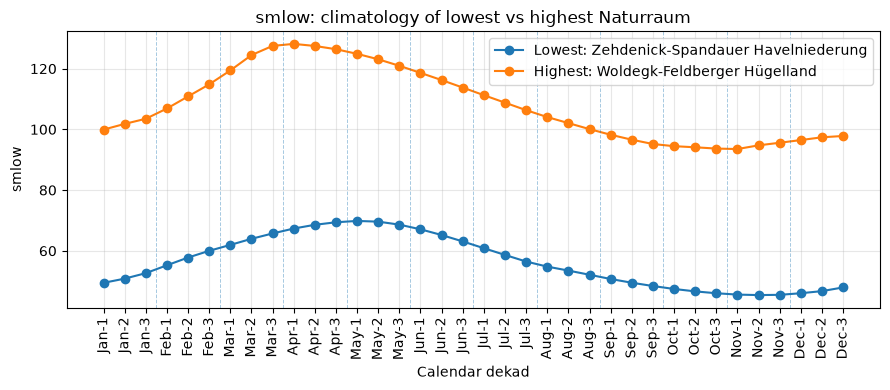

In [13]:
# plot highest/lowest NR
x = np.arange(36)

for name, ds in variables.items():

    regional_mean = ds["mean"].mean(dim=["month", "dekad"])

    min_region = regional_mean.idxmin(dim="region_id").item()
    max_region = regional_mean.idxmax(dim="region_id").item()

    min_name = natraum_3035.loc[
        natraum_3035["region_id"] == min_region,
        "NAME_UNTER"
    ].iloc[0]

    max_name = natraum_3035.loc[
        natraum_3035["region_id"] == max_region,
        "NAME_UNTER"
    ].iloc[0]

    min_cycle = (
        ds["mean"]
        .sel(region_id=min_region)
        .values
        .reshape(36)
    )

    max_cycle = (
        ds["mean"]
        .sel(region_id=max_region)
        .values
        .reshape(36)
    )

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.plot(
        x,
        min_cycle,
        marker="o",
        label=f"Lowest: {min_name}",
    )

    ax.plot(
        x,
        max_cycle,
        marker="o",
        label=f"Highest: {max_name}",
    )

    ax.set_title(
        f"{name}: climatology of lowest vs highest Naturraum"
    )

    ax.set_xlabel("Calendar dekad")
    ax.set_ylabel(name)

    ax.set_xticks(x)
    ax.set_xticklabels(dekad_labels, rotation=90)

    for month in range(1, 12):
        ax.axvline(
            month * 3 - 0.5,
            linestyle="--",
            linewidth=0.7,
            alpha=0.4,
        )

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


In [16]:
# spatial distribution
# code by ChatGPT
def plot_naturraum_climatology(
    climatology,
    variable,
    month=7,
    dekad=3,
    polygons=natraum_3035,
    figsize=(7, 5),
):
    values = (
        climatology["mean"]
        .sel(month=month, dekad=dekad)
        .to_dataframe(name=variable)
        .reset_index()
    )

    plot_data = polygons.merge(
        values,
        on="region_id",
        how="left",
        validate="one_to_one",
    )

    fig, ax = plt.subplots(figsize=figsize)

    plot_data.plot(
        column=variable,
        ax=ax,
        legend=True,
        edgecolor="black",
        linewidth=0.4,
        missing_kwds={"color": "lightgrey"},
    )

    ax.set_title(
        f"{variable} climatological mean — Jul-3\n"
        f"2001–2025"
    )
    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

    return plot_data

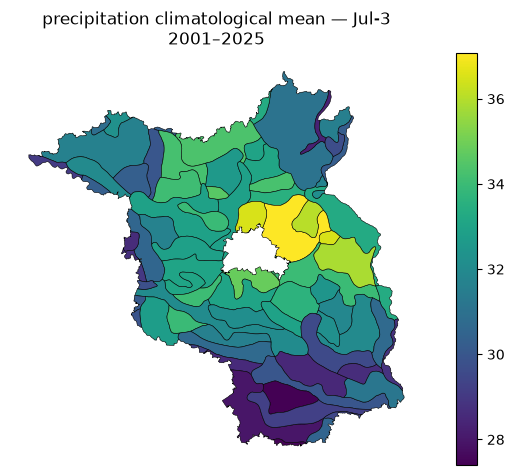

In [17]:
pr_jul3 = plot_naturraum_climatology(
    pr_dekad,
    variable="precipitation",
    month=7,
    dekad=3,
)

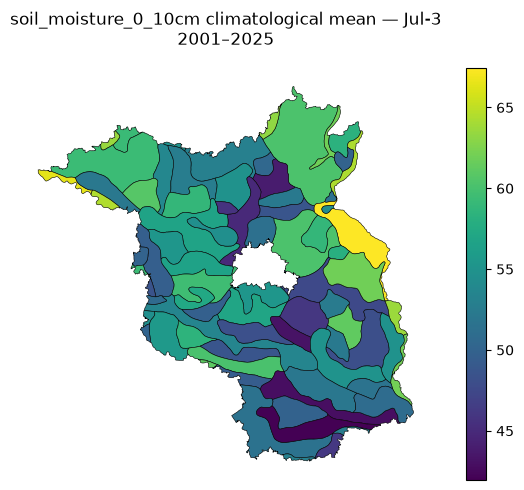

In [18]:
smtop_jul3 = plot_naturraum_climatology(
    smtop_dekad,
    variable="soil_moisture_0_10cm",
    month=7,
    dekad=3,
)

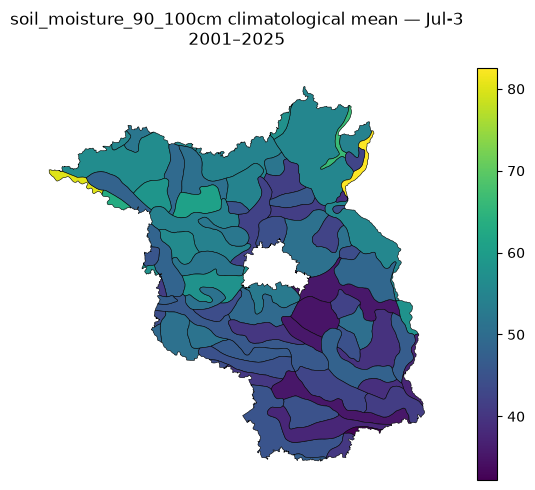

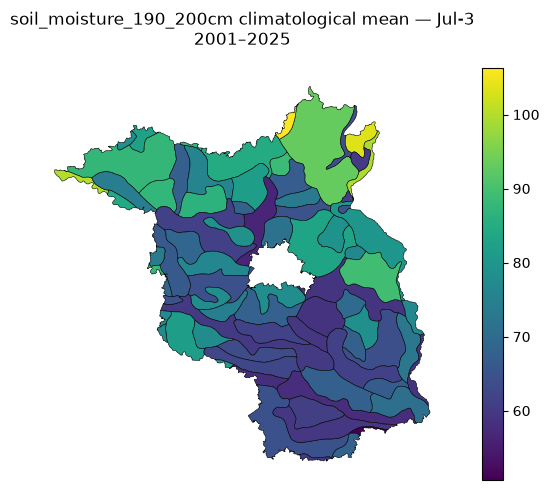

In [21]:
smmid_jul3 = plot_naturraum_climatology(
    smmid_dekad,
    variable="soil_moisture_90_100cm",
    month=7,
    dekad=3,
)

smlow_jul3 = plot_naturraum_climatology(
    smlow_dekad,
    variable="soil_moisture_190_200cm",
    month=7,
    dekad=3,
)

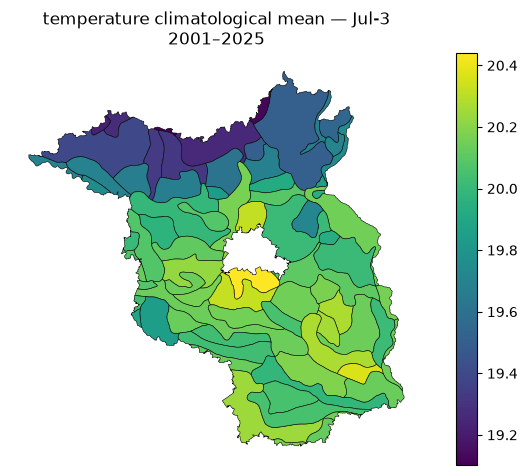

In [22]:
tas_jul3 = plot_naturraum_climatology(
    tas_dekad,
    variable="temperature",
    month=7,
    dekad=3,
)

In [23]:
print(pr_jul3["precipitation"].notna().sum())
print(tas_jul3["temperature"].notna().sum())
print(smtop_jul3["soil_moisture_0_10cm"].notna().sum())

79
79
79


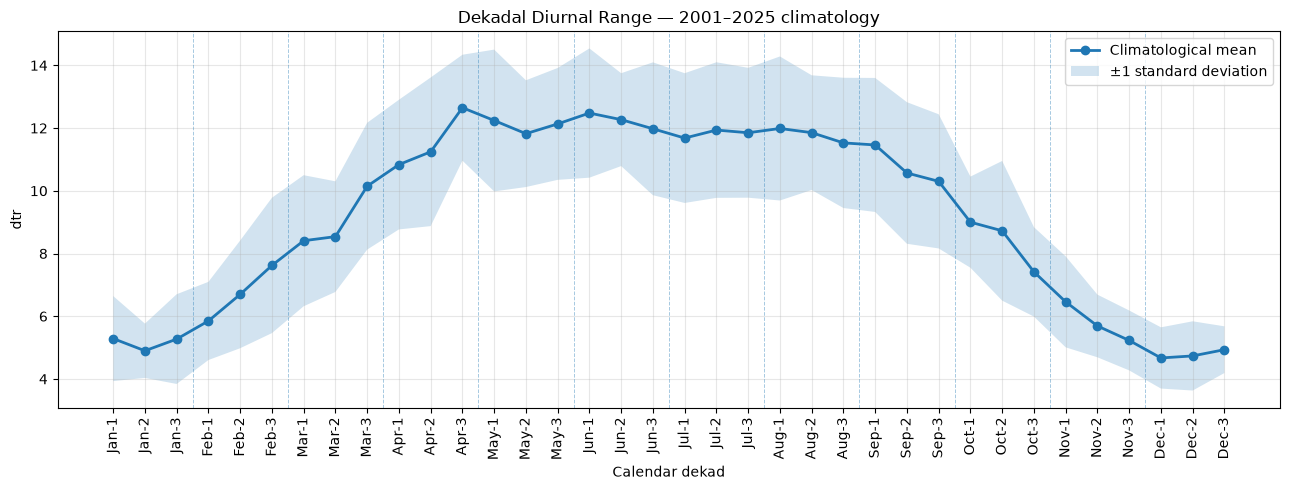

In [3]:
month_names = [    "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
dekad_labels = [
    f"{month_names[m-1]}-{d}"
    for m in range(1, 13)
    for d in range(1, 4)
]
# Code by ChatGPT
x = np.arange(36)

variable_labels = {
    "dtr": "Dekadal Diurnal Range",
    }

variables = {
    "dtr":dtr_clim,
    }

for name, ds in variables.items():

    # Average the climatology across the 79 Naturräume
    mean = ds["mean"].mean(dim="region_id").values
    std = ds["std"].mean(dim="region_id").values

    # Flatten month/dekad dimensions into the 36 calendar dekads
    mean = mean.reshape(36)
    std = std.reshape(36)

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        x,
        mean,
        marker="o",
        linewidth=2,
        label="Climatological mean",
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.2,
        label="±1 standard deviation",
    )

    ax.set_title(
        f"{variable_labels[name]} — 2001–2025 climatology"
    )
    ax.set_xlabel("Calendar dekad")
    ax.set_ylabel(name)

    ax.set_xticks(x)
    ax.set_xticklabels(dekad_labels, rotation=90)

    # Show month boundaries
    for month in range(1, 12):
        ax.axvline(
            month * 3 - 0.5,
            linestyle="--",
            linewidth=0.7,
            alpha=0.4,
        )

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

# Anomaly Calculation

In [11]:
tas_clima = tas_dekad.copy()
tas_dek_dat = xr.open_dataset("../data/processed/tas_mean_dekadal_natraum_2001_2025.nc")
tas_dek_dat["tas"]

<xarray.DataArray 'tas' (region_id: 79, year: 25, month: 12, dekad: 3)> Size: 569kB
[71100 values with dtype=float64]
Coordinates:
  * region_id  (region_id) float64 632B 1.0 2.0 3.0 4.0 ... 76.0 77.0 78.0 79.0
  * year       (year) int32 100B 2001 2002 2003 2004 ... 2022 2023 2024 2025
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Attributes:
    standard_name:      air_temperature
    long_name:          Daily Mean Air Temperature
    units:              degree_Celsius
    grid_mapping:       crs
    cell_methods:       time: mean
    units_metadata:     temperature: on-scale
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...

In [12]:
tas_clima = tas_clima.assign_coords(region_id=tas_clima.region_id.astype(int))
natraum_3035["region_id"] = natraum_3035["region_id"].astype(int)

In [14]:
tas_clima_1 = tas_clima.sel(region_id=1)
tas_dek_dat1 = tas_dek_dat.sel(region_id=1)

mean_anomaly = tas_dek_dat1 - tas_clima_1["mean"]
std_anomaly = mean_anomaly / tas_clima_1["std"]

print(std_anomaly.dims, std_anomaly.sizes)

FrozenMappingWarningOnValuesAccess({'year': 25, 'month': 12, 'dekad': 3}) Frozen({'year': 25, 'month': 12, 'dekad': 3})


In [15]:
print("tas raw dekad dims:", tas_dek_dat1.dims)          # expect region_id, year, month, dekad
print("tas climatology dims:", tas_clima_1.dims)  # expect region_id, month, dekad — no year
print("tas climatology data_vars:", list(tas_clima_1.data_vars))  # expect ['mean', 'std', maybe 'n_years']

tas raw dekad dims: FrozenMappingWarningOnValuesAccess({'year': 25, 'month': 12, 'dekad': 3})
tas climatology dims: FrozenMappingWarningOnValuesAccess({'month': 12, 'dekad': 3})
tas climatology data_vars: ['mean', 'std', 'n_years']


<xarray.DataArray 'tas' ()> Size: 8B
array(-6.31593543e-17)
Coordinates:
    region_id  float64 8B 1.0
Attributes:
    standard_name:      air_temperature
    long_name:          Daily Mean Air Temperature
    units:              degree_Celsius
    grid_mapping:       crs
    cell_methods:       time: mean
    units_metadata:     temperature: on-scale
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...
<xarray.DataArray 'tas' ()> Size: 8B
array(1.)
Coordinates:
    region_id  float64 8B 1.0
Attributes:
    standard_name:      air_temperature
    long_name:          Daily Mean Air Temperature
    units:              degree_Celsius
    grid_mapping:       crs
    cell_methods:       time: mean
    units_metadata:     temperature: on-scale
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM

(array([  6.,  18.,  59., 111., 179., 188., 154., 126.,  43.,  16.]),
 array([-3.05398587, -2.48963921, -1.92529255, -1.36094589, -0.79659924,
        -0.23225258,  0.33209408,  0.89644074,  1.46078739,  2.02513405,
         2.58948071]),
 <BarContainer object of 10 artists>)

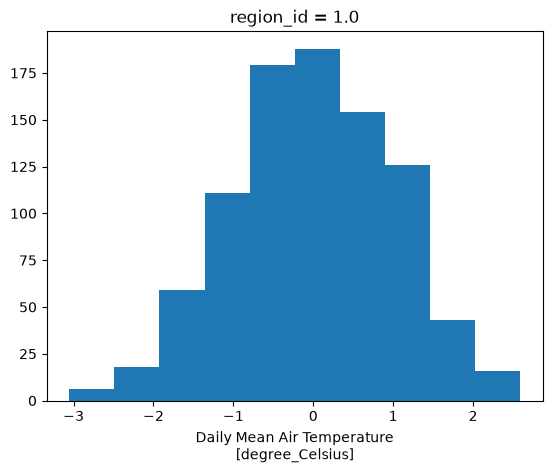

In [ ]:
print(std_anomaly["tas"].mean(skipna=True))   # expect ~0
print(std_anomaly["tas"].std(skipna=True))    # expect ~1
print(std_anomaly["tas"].isnull().sum())      # expect 0, or small 

std_anomaly["tas"].plot() 

<xarray.DataArray 'tas' ()> Size: 8B
array(4.73695157e-17)
Coordinates:
    region_id  float64 8B 78.0
Attributes:
    standard_name:      air_temperature
    long_name:          Daily Mean Air Temperature
    units:              degree_Celsius
    grid_mapping:       crs
    cell_methods:       time: mean
    units_metadata:     temperature: on-scale
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...
<xarray.DataArray 'tas' ()> Size: 8B
array(1.)
Coordinates:
    region_id  float64 8B 78.0
Attributes:
    standard_name:      air_temperature
    long_name:          Daily Mean Air Temperature
    units:              degree_Celsius
    grid_mapping:       crs
    cell_methods:       time: mean
    units_metadata:     temperature: on-scale
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATU

(array([  6.,  16.,  63., 126., 173., 199., 161., 107.,  39.,  10.]),
 array([-3.10059082, -2.516589  , -1.93258718, -1.34858536, -0.76458354,
        -0.18058172,  0.4034201 ,  0.98742192,  1.57142374,  2.15542556,
         2.73942738]),
 <BarContainer object of 10 artists>)

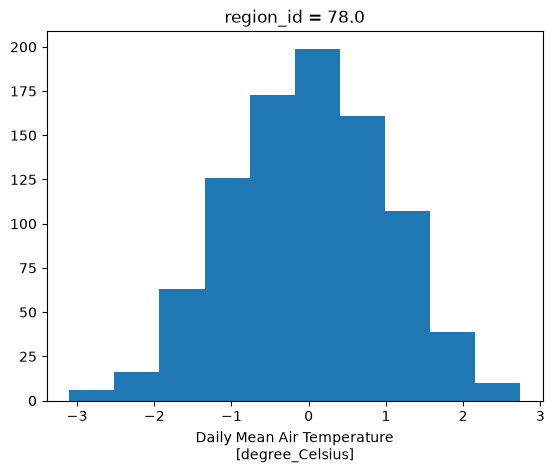

In [24]:
## another test for different region
tas_clima_78 = tas_clima.sel(region_id=78)
tas_dek_dat78 = tas_dek_dat.sel(region_id=78)

mean_anomaly = tas_dek_dat78 - tas_clima_78["mean"]
std_anomaly = mean_anomaly / tas_clima_78["std"]

print(std_anomaly["tas"].mean(skipna=True))   # expect ~0
print(std_anomaly["tas"].std(skipna=True))    # expect ~1
print(std_anomaly["tas"].isnull().sum())      # expect 0, or small 

std_anomaly["tas"].plot() 

In [ ]:
# run for all 79 NR
tas_clima_all = tas_clima.assign_coords(region_id=tas_clima.region_id.astype(int))
tas_anomaly_all = (tas_dek_dat - tas_clima_all["mean"]) / tas_clima_all["std"]

print(float(tas_anomaly_all["tas"].mean(skipna=True)))
print(float(tas_anomaly_all["tas"].std(skipna=True)))
print(int(tas_anomaly_all["tas"].isnull().sum()), "/", tas_anomaly_all["tas"].size) # no NAs yaaay :)

-1.1592539711416543e-17
1.0
0 / 71100


Text(0.5, 1.0, 'tas standardized anomaly, region 2')

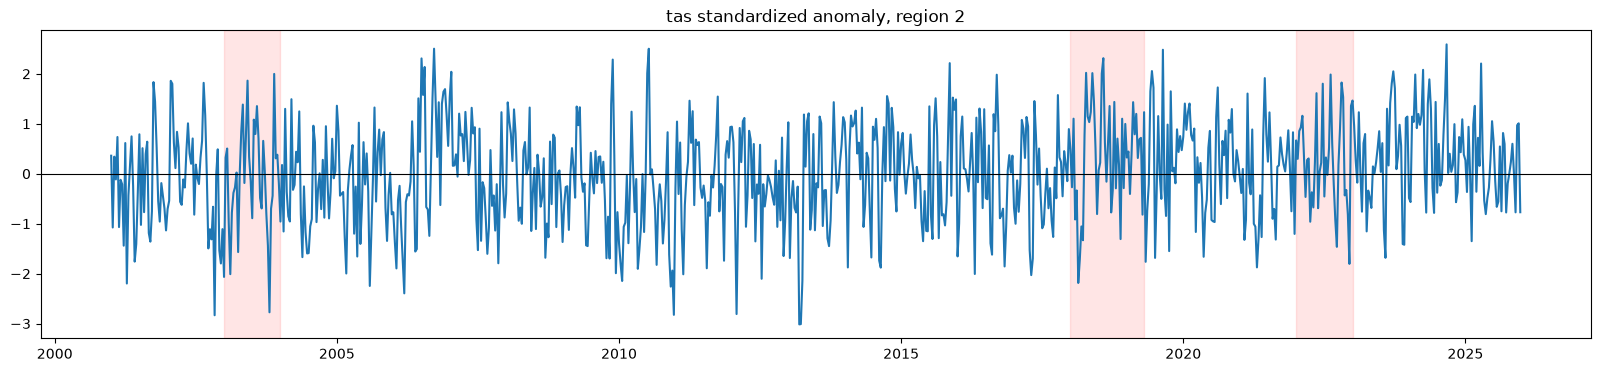

In [32]:
# plot a timeseries for just one region and visually check for known drought years
# code by ChatGPT
anom_2 = tas_anomaly_all.sel(region_id=2)["tas"]
anom_2_df = anom_2.to_dataframe().reset_index()
anom_2_df["t"] = anom_2_df["year"] + (anom_2_df["month"]-1)/12 + (anom_2_df["dekad"]-1)/36
anom_2_df = anom_2_df.sort_values("t")

plt.figure(figsize=(20,4))
plt.plot(anom_2_df["t"], anom_2_df["tas"])
plt.axhline(0, color="black", lw=0.8)
plt.axvspan(2003,2004, color="red", alpha=0.1)
plt.axvspan(2018, 2019.3, color="red", alpha=0.1)  # flag the known drought window
plt.axvspan(2022,2023, color="red", alpha=0.1)
plt.title("tas standardized anomaly, region 2")

# Standardization